<a href="https://colab.research.google.com/github/jmarquez90/clip-siglip-memetic-analysis/blob/master/hateful-memes-clip-siglip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparing CLIP and SigLIP for hateful-meme classification

This notebook compares a Concat BERT literature baseline with six fusion-specific linear-probe evaluation (LPE) systems: projected concatenation, aligned element-wise interaction, and full cross interaction for both CLIP and SigLIP. The CLIP and SigLIP encoders remain frozen, and the linear readout is the primary prediction method.

The three fixed fusion feature maps are:

- **concat**, which joins the image and text embeddings;
- **align**, which takes their element-wise product; and
- **cross**, whose linear readout is implemented as a bilinear layer over the full outer-product feature space without materializing that large feature matrix.

After the seven primary models, six nonlinear projected-fusion classifiers repeat the same encoder/fusion combinations without LPE. These direct classifiers are ablations used to test whether the linear readout or a learned nonlinear head better exploits each frozen representation.

> **Content warning:** the source dataset contains hateful and discriminatory material. Example rendering is disabled by default. The dataset is not redistributed by this repository.


## 1. Environment and data layout

The reference environment uses Python 3.10+ and the versions in `requirements.txt`. The first code cell is a self-contained Colab bootstrap: in Colab it preserves the runtime's compiled scientific stack and installs only the model-specific dependencies; in a local checkout it uses `requirements.txt`. It also mounts Google Drive when available. A GPU is recommended for embedding extraction; the linear probes run on CPU.

Download the Hateful Memes dataset from its authorized source and arrange it as follows:

```text
<HATEFUL_MEMES_DATA_ROOT>/
└── hateful-memes/
    ├── train.jsonl
    ├── dev_seen.jsonl
    ├── test_seen.jsonl
    └── img/
        └── ...
```

Set `HATEFUL_MEMES_DATA_ROOT` to either the extracted `hateful-memes` directory or its parent. In Colab, the placeholder below points to a user-owned Drive folder without exposing a private URL or folder hierarchy. While this repository is private, add a fine-grained GitHub token with read-only Contents access to Colab Secrets as `GH_TOKEN` and enable notebook access; the bootstrap uses it without saving the token in the notebook.


In [3]:
from time import perf_counter

RUN_STARTED_AT = perf_counter()

In [2]:
# Colab/local bootstrap: safe to run before importing third-party packages.
import base64
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

LOCAL_PACKAGES = [
    "kagglehub==1.0.2",
    "matplotlib==3.10.7",
    "numpy==2.2.6",
    "pandas==2.3.3",
    "Pillow==11.3.0",
    "scikit-learn==1.7.2",
    "seaborn==0.13.2",
    "sentencepiece==0.2.2",
    "torchvision>=0.17,<1",
    "tqdm==4.67.1",
    "transformers==4.57.6",
]

COLAB_MODEL_PACKAGES = [
    "kagglehub==1.0.2",
    "sentencepiece==0.2.2",
    "transformers==4.57.6",
]
COLAB_RUNTIME_PACKAGES = {
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "Pillow",
    "sklearn": "scikit-learn",
    "seaborn": "seaborn",
    "torch": "torch",
    "torchvision": "torchvision",
    "tqdm": "tqdm",
}
IN_COLAB_BOOTSTRAP = importlib.util.find_spec("google.colab") is not None

skip_install = os.environ.get("SKIP_NOTEBOOK_INSTALL", "false").casefold() == "true"
if not skip_install:
    requirements_path = Path("requirements.txt")
    if IN_COLAB_BOOTSTRAP:
        missing_runtime_packages = [
            package
            for module, package in COLAB_RUNTIME_PACKAGES.items()
            if importlib.util.find_spec(module) is None
        ]
        install_command = [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--upgrade-strategy",
            "only-if-needed",
            *COLAB_MODEL_PACKAGES,
            *missing_runtime_packages,
        ]
    elif requirements_path.exists():
        install_command = [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(requirements_path)]
    else:
        install_command = [sys.executable, "-m", "pip", "install", "--quiet", *LOCAL_PACKAGES]
        if importlib.util.find_spec("torch") is None:
            install_command.append("torch>=2.2,<3")
    subprocess.check_call(install_command)

try:
    from google.colab import drive
except ModuleNotFoundError:
    print("Local runtime detected; Google Drive was not mounted.")
else:
    skip_mount = os.environ.get("SKIP_GOOGLE_DRIVE_MOUNT", "false").casefold() == "true"
    if not skip_mount:
        drive.mount("/content/drive", force_remount=False)
    print("Colab runtime detected. Select a GPU under Runtime > Change runtime type.")

def clone_notebook_repository(repository_url, repository_root):
    from google.colab import userdata

    try:
        github_token = userdata.get("GH_TOKEN")
    except Exception:
        github_token = None

    clone_environment = None
    if github_token:
        basic_credential = base64.b64encode(
            f"x-access-token:{github_token}".encode("utf-8")
        ).decode("ascii")
        clone_environment = os.environ.copy()
        clone_environment.update(
            {
                "GIT_CONFIG_COUNT": "1",
                "GIT_CONFIG_KEY_0": "http.https://github.com/.extraheader",
                "GIT_CONFIG_VALUE_0": f"AUTHORIZATION: basic {basic_credential}",
            }
        )
    clone_result = subprocess.run(
        ["git", "clone", "--depth", "1", repository_url, str(repository_root)],
        check=False,
        capture_output=True,
        env=clone_environment,
        text=True,
    )
    if clone_result.returncode != 0:
        git_message = clone_result.stderr.strip() or "Git did not return an error message."
        token_help = (
            "Check that GH_TOKEN can read this repository."
            if github_token
            else "Add a read-only GitHub token to Colab Secrets as GH_TOKEN and enable notebook access."
        )
        raise RuntimeError(f"Could not clone the repository. {token_help} Git reported: {git_message}")


REQUIRED_MODEL_MODULES = (
    Path("models/concat_bert.py"),
    Path("models/fusion.py"),
)
missing_model_modules = [path for path in REQUIRED_MODEL_MODULES if not path.is_file()]
if missing_model_modules and IN_COLAB_BOOTSTRAP:
    repository_url = "https://github.com/jmarquez90/clip-siglip-memetic-analysis.git"
    repository_root = Path(
        os.environ.get(
            "NOTEBOOK_REPO_ROOT",
            "/content/clip-siglip-memetic-analysis",
        )
    )
    repository_modules = [repository_root / path for path in REQUIRED_MODEL_MODULES]
    if not all(path.is_file() for path in repository_modules):
        if repository_root.exists():
            raise FileNotFoundError(
                f"{repository_root} exists but does not contain every required model module. "
                "Update that checkout or set NOTEBOOK_REPO_ROOT to the current repository."
            )
        clone_notebook_repository(repository_url, repository_root)
    sys.path.insert(0, str(repository_root))


Mounted at /content/drive
Colab runtime detected. Select a GPU under Runtime > Change runtime type.


In [4]:
import json
import os
import random
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoProcessor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
COLAB_DATA_ROOT = "/content/drive/MyDrive/clip-siglip-memetic-analysis/data"
COLAB_ARTIFACT_ROOT = "/content/drive/MyDrive/clip-siglip-memetic-analysis/clip-siglip-artifacts"
DEFAULT_DATA_ROOT = COLAB_DATA_ROOT if IN_COLAB else "data"
DEFAULT_ARTIFACT_ROOT = COLAB_ARTIFACT_ROOT if IN_COLAB else "artifacts"
DATA_ROOT = Path(
    os.environ.get(
        "HATEFUL_MEMES_DATA_ROOT",
        DEFAULT_DATA_ROOT,
    )
).expanduser()
ARTIFACT_DIR = Path(os.environ.get("HATEFUL_MEMES_ARTIFACT_ROOT", DEFAULT_ARTIFACT_ROOT)).expanduser()
EMBEDDING_DIR = ARTIFACT_DIR / "embeddings"
MODEL_DIR = ARTIFACT_DIR / "models"
ARTIFACT_DIR.mkdir(exist_ok=True)
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_IDS = {
    "CLIP": "openai/clip-vit-base-patch32",
    "SigLIP": "google/siglip-base-patch16-224",
}
LABELED_TEST_FILENAME = "test_seen.jsonl"
SPLIT_FILES = {
    "train": ("train.jsonl",),
    "dev": ("dev_seen.jsonl", "dev.jsonl"),
    "test": (LABELED_TEST_FILENAME, "test.jsonl"),
}


def get_split_path(dataset_dir, split_name):
    return next(
        (
            dataset_dir / filename
            for filename in SPLIT_FILES[split_name]
            if (dataset_dir / filename).is_file()
        ),
        None,
    )


def dataset_layout_exists(dataset_dir):
    return (dataset_dir / "img").is_dir() and all(
        get_split_path(dataset_dir, split_name) is not None for split_name in SPLIT_FILES
    )


KAGGLE_DATASET_ROOT = DATA_ROOT / "hateful-memes-kaggle"
DATASET_CANDIDATES = [
    DATA_ROOT,
    DATA_ROOT / "hateful-memes",
    KAGGLE_DATASET_ROOT,
    KAGGLE_DATASET_ROOT / "data",
]
DATASET_DIR = next(
    (
        candidate
        for candidate in DATASET_CANDIDATES
        if dataset_layout_exists(candidate)
    ),
    KAGGLE_DATASET_ROOT,
)
BATCH_SIZE = 64 if DEVICE.type == "cuda" else 8
NUM_WORKERS = 0
FORCE_RECOMPUTE = False
SHOW_EXAMPLES = os.environ.get("SHOW_HATEFUL_MEME_EXAMPLES", "false").casefold() == "true"

print(f"Device: {DEVICE}")
print(f"Dataset directory: {DATASET_DIR}")


Device: cuda
Dataset directory: /content/drive/MyDrive/clip-siglip-memetic-analysis/data/hateful-memes-kaggle/data


## 2. Acquire the licensed dataset

The Hateful Memes images are not redistributed with this repository. If the expected files are absent, the next cell downloads the public Kaggle mirror as one archive, avoiding per-image API requests and shared-IP rate limits. Kaggle's `test.jsonl` is unlabeled, so the cell reuses an existing `test_seen.jsonl` when available or fetches that single small annotation file from a pinned Hugging Face revision. Read the linked agreement before continuing: accessing the files constitutes acceptance, and the dataset has use and redistribution restrictions. The image download is approximately 3.6 GB and is extracted into the configured data directory.


In [5]:
import shutil
import urllib.request

import kagglehub

KAGGLE_DATASET_HANDLE = "parthplc/facebook-hateful-meme-dataset"
DATASET_LICENSE_URL = "https://www.drivendata.org/competitions/64/hateful-memes/"
TEST_SEEN_ANNOTATIONS_URL = (
    "https://huggingface.co/datasets/panjiyarsunil/hateful-memes-data/resolve/"
    f"759279f46912fafad49dfef472924e899198ec69/{LABELED_TEST_FILENAME}"
)
LICENSE_ACCEPTANCE_PHRASE = "I ACCEPT"


def dataset_is_ready(path):
    image_dir = path / "img"
    if not dataset_layout_exists(path):
        return False
    return sum(1 for image_path in image_dir.glob("*.png") if image_path.is_file()) >= 10_000


if not dataset_is_ready(DATASET_DIR):
    print("The Hateful Memes dataset is not present.")
    print(f"Review the dataset license before downloading: {DATASET_LICENSE_URL}")
    accepted = os.environ.get("HATEFUL_MEMES_LICENSE_ACCEPTED", "").strip().upper()
    if not accepted and IN_COLAB:
        accepted = input(
            f"Type {LICENSE_ACCEPTANCE_PHRASE!r} to accept the license and download the dataset: "
        ).strip().upper()
    if accepted != LICENSE_ACCEPTANCE_PHRASE:
        raise RuntimeError(
            "Dataset download cancelled. After reviewing the license, type 'I ACCEPT' when prompted "
            "or set HATEFUL_MEMES_LICENSE_ACCEPTED=I ACCEPT in a trusted private environment."
        )

    print(f"Downloading {KAGGLE_DATASET_HANDLE} as a single archive...")
    download_path = Path(
        kagglehub.dataset_download(
            KAGGLE_DATASET_HANDLE,
            output_dir=str(KAGGLE_DATASET_ROOT),
        )
    )
    downloaded_candidates = [
        download_path,
        download_path / "data",
        KAGGLE_DATASET_ROOT,
        KAGGLE_DATASET_ROOT / "data",
    ]
    DATASET_CANDIDATES.extend(
        candidate for candidate in downloaded_candidates if candidate not in DATASET_CANDIDATES
    )
    DATASET_DIR = next(
        (candidate for candidate in downloaded_candidates if dataset_is_ready(candidate)),
        KAGGLE_DATASET_ROOT,
    )

if not dataset_is_ready(DATASET_DIR):
    raise FileNotFoundError(
        f"The Kaggle download did not produce the expected files under {KAGGLE_DATASET_ROOT}. "
        "Inspect the Kaggle dataset page or rerun this cell after clearing an incomplete download."
    )

labeled_test_path = DATASET_DIR / LABELED_TEST_FILENAME
if not labeled_test_path.is_file():
    existing_test_annotations = next(
        (
            candidate / LABELED_TEST_FILENAME
            for candidate in DATASET_CANDIDATES
            if (candidate / LABELED_TEST_FILENAME).is_file()
        ),
        None,
    )
    if existing_test_annotations is not None:
        shutil.copy2(existing_test_annotations, labeled_test_path)
        print(f"Reused labeled test annotations from {existing_test_annotations}")
    else:
        temporary_test_path = labeled_test_path.with_suffix(".jsonl.download")
        urllib.request.urlretrieve(TEST_SEEN_ANNOTATIONS_URL, temporary_test_path)
        temporary_test_path.replace(labeled_test_path)
        print(f"Downloaded the labeled {LABELED_TEST_FILENAME} annotation file.")

print(f"Dataset ready: {DATASET_DIR}")


Dataset ready: /content/drive/MyDrive/clip-siglip-memetic-analysis/data/hateful-memes-kaggle/data


## 3. Load and validate the official splits

Only the original `text` and binary `label` fields are used. Enhanced gold annotations are intentionally excluded: protected-class or attack-type labels derived during annotation may not be available at inference time and can leak privileged information into the classifier.


In [6]:
REQUIRED_COLUMNS = {"id", "img", "text", "label"}


def load_split(split_name):
    path = get_split_path(DATASET_DIR, split_name)
    if path is None:
        checked_locations = "\n".join(f"  - {candidate}" for candidate in DATASET_CANDIDATES)
        raise FileNotFoundError(
            f"Could not find the extracted Hateful Memes splits. Checked:\n{checked_locations}\n"
            "Set HATEFUL_MEMES_DATA_ROOT to either the dataset directory itself or its parent. "
            "The selected directory must contain train.jsonl, dev/test JSONL files, and img/."
        )
    frame = pd.read_json(path, lines=True)
    missing = REQUIRED_COLUMNS.difference(frame.columns)
    if missing:
        if split_name == "test" and "label" in missing:
            raise ValueError(
                f"{path.name} is the unlabeled challenge test file. "
                f"Rerun the dataset-acquisition cell to obtain {LABELED_TEST_FILENAME}."
            )
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")
    frame = frame.loc[:, ["id", "img", "text", "label"]].copy()
    frame["label"] = frame["label"].astype(int)
    if not set(frame["label"].unique()).issubset({0, 1}):
        raise ValueError(f"{path.name} contains labels outside {{0, 1}}")
    return frame.reset_index(drop=True)


splits = {name: load_split(name) for name in SPLIT_FILES}

split_summary = pd.DataFrame(
    {
        name: {
            "rows": len(frame),
            "hateful": int(frame["label"].sum()),
            "hateful_rate": frame["label"].mean(),
        }
        for name, frame in splits.items()
    }
).T
split_summary


,rows,hateful,hateful_rate
train,8500.0,3050.0,0.358824
dev,500.0,250.0,0.500000
test,1000.0,490.0,0.490000


In [7]:
# Verify that examples do not cross split boundaries.
split_names = list(splits)
for left_index, left_name in enumerate(split_names):
    for right_name in split_names[left_index + 1:]:
        overlap = set(splits[left_name]["id"]) & set(splits[right_name]["id"])
        assert not overlap, f"ID leakage between {left_name} and {right_name}: {len(overlap)}"

print("Split integrity check passed: no overlapping IDs.")


Split integrity check passed: no overlapping IDs.


In [8]:
def resolve_image_path(relative_path):
    path = DATASET_DIR / Path(relative_path)
    if not path.exists():
        raise FileNotFoundError(f"Missing image: {path}")
    return path


def show_dataset_examples(frame, count=6):
    sample = frame.sample(min(count, len(frame)), random_state=SEED)
    columns = 3
    rows = int(np.ceil(len(sample) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(14, 4 * rows))
    axes = np.asarray(axes).reshape(-1)
    for axis, (_, row) in zip(axes, sample.iterrows()):
        axis.imshow(Image.open(resolve_image_path(row["img"])).convert("RGB"))
        axis.set_title(f"id={row['id']} | label={row['label']}\n{row['text'][:90]}")
        axis.axis("off")
    for axis in axes[len(sample):]:
        axis.axis("off")
    plt.tight_layout()


if SHOW_EXAMPLES:
    show_dataset_examples(splits["train"])
else:
    print("Example rendering is disabled. Set SHOW_EXAMPLES=True after reviewing the content warning.")


Example rendering is disabled. Set SHOW_EXAMPLES=True after reviewing the content warning.


## 4. Extract frozen CLIP and SigLIP embeddings

Each pretrained model produces an image embedding and a text embedding for every example. Both vectors are L2-normalized and cached so all fusion-specific LPE and direct-classifier experiments use exactly the same frozen representations without rerunning the encoders.


In [9]:
class HatefulMemesDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = Image.open(resolve_image_path(row["img"])).convert("RGB")
        return {
            "id": int(row["id"]),
            "image": image,
            "text": str(row["text"]),
            "label": int(row["label"]),
        }


def collate_examples(examples):
    return {
        "ids": np.asarray([example["id"] for example in examples]),
        "images": [example["image"] for example in examples],
        "texts": [example["text"] for example in examples],
        "labels": np.asarray([example["label"] for example in examples], dtype=np.int64),
    }


def cache_path(model_name, split_name):
    safe_name = MODEL_IDS[model_name].replace("/", "--")
    return EMBEDDING_DIR / f"{safe_name}--{split_name}.npz"


def encode_split(model_name, split_name, frame, model, processor):
    destination = cache_path(model_name, split_name)
    if destination.exists() and not FORCE_RECOMPUTE:
        cached = np.load(destination)
        if len(cached["labels"]) == len(frame):
            return {key: cached[key] for key in cached.files}

    loader = DataLoader(
        HatefulMemesDataset(frame),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        collate_fn=collate_examples,
    )
    all_ids, all_labels, all_image, all_text = [], [], [], []
    for batch in tqdm(loader, desc=f"{model_name} / {split_name}"):
        inputs = processor(
            images=batch["images"],
            text=batch["texts"],
            padding=True,
            truncation=True,
            return_tensors="pt",
        )
        pixel_values = inputs["pixel_values"].to(DEVICE)
        text_inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
            if key in {"input_ids", "attention_mask"}
        }
        with torch.inference_mode():
            image_features = model.get_image_features(pixel_values=pixel_values)
            text_features = model.get_text_features(**text_inputs)
            image_features = F.normalize(image_features, dim=-1)
            text_features = F.normalize(text_features, dim=-1)

        all_ids.append(batch["ids"])
        all_labels.append(batch["labels"])
        all_image.append(image_features.cpu().numpy())
        all_text.append(text_features.cpu().numpy())

    bundle = {
        "ids": np.concatenate(all_ids),
        "labels": np.concatenate(all_labels),
        "image": np.concatenate(all_image),
        "text": np.concatenate(all_text),
    }
    np.savez_compressed(destination, **bundle)
    return bundle


def extract_model_embeddings(model_name):
    model_id = MODEL_IDS[model_name]
    processor = AutoProcessor.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id).to(DEVICE).eval()
    encoded = {
        split_name: encode_split(model_name, split_name, frame, model, processor)
        for split_name, frame in splits.items()
    }
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return encoded


In [10]:
embeddings = {
    model_name: extract_model_embeddings(model_name)
    for model_name in MODEL_IDS
}

embedding_shapes = pd.DataFrame(
    [
        {
            "model": model_name,
            "split": split_name,
            "image_shape": bundle["image"].shape,
            "text_shape": bundle["text"].shape,
        }
        for model_name, model_splits in embeddings.items()
        for split_name, bundle in model_splits.items()
    ]
)
embedding_shapes


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


vocab.json: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/813M [00:00<?, ?B/s]

,model,split,image_shape,text_shape
0,CLIP,train,"(8500, 512)","(8500, 512)"
1,CLIP,dev,"(500, 512)","(500, 512)"
2,CLIP,test,"(1000, 512)","(1000, 512)"
3,SigLIP,train,"(8500, 768)","(8500, 768)"
4,SigLIP,dev,"(500, 768)","(500, 768)"
5,SigLIP,test,"(1000, 768)","(1000, 768)"


## 5. Define shared evaluation helpers

The held-out labels and stratified-bootstrap helper are defined before model training so the baseline, primary LPE systems, and direct-fusion ablations share one evaluation protocol. All ROC-AUC and average-precision values use continuous probabilities.


In [11]:
test_labels = splits["test"]["label"].to_numpy(dtype=np.int64)


### Shared bootstrap uncertainty helper

We use stratified bootstrap resampling of held-out predictions to estimate 95% confidence intervals for ROC-AUC and average precision. Models are not retrained during this procedure.


In [12]:
def stratified_bootstrap_scores(
    y_true,
    prediction_sets,
    metric,
    n_resamples=2_000,
    confidence=0.95,
    seed=SEED,
):
    y_true = np.asarray(y_true)
    positive_indices = np.flatnonzero(y_true == 1)
    negative_indices = np.flatnonzero(y_true == 0)
    rng = np.random.default_rng(seed)

    samples = {name: [] for name in prediction_sets}

    for _ in range(n_resamples):
        sampled_indices = np.concatenate(
            [
                rng.choice(
                    positive_indices,
                    size=len(positive_indices),
                    replace=True,
                ),
                rng.choice(
                    negative_indices,
                    size=len(negative_indices),
                    replace=True,
                ),
            ]
        )

        for name, probabilities in prediction_sets.items():
            samples[name].append(
                metric(
                    y_true[sampled_indices],
                    np.asarray(probabilities)[sampled_indices],
                )
            )

    alpha = (1.0 - confidence) / 2.0
    return {
        name: {
            "lower": np.quantile(values, alpha),
            "upper": np.quantile(values, 1.0 - alpha),
        }
        for name, values in samples.items()
    }

In [13]:
BOOTSTRAP_RESAMPLES = 2_000


## 6. Train the Concat BERT literature baseline

Concat BERT is trained as a separate end-to-end model rather than as another probe over CLIP features. It adapts DrivenData's public [mid-level concatenation scaffold](https://drivendata.co/blog/hateful-memes-benchmark) to the Concat BERT baseline described by [Kiela et al.](https://arxiv.org/abs/2005.04790), combining a BERT text encoder with an ImageNet-pretrained ResNet-152 image encoder. Each branch is projected to 300 features, the two vectors are concatenated, and a dropout-separated MLP produces the binary logits. DrivenData's original demonstration used fixed fastText embeddings rather than BERT, so it is cited as an implementation scaffold rather than as an exact architecture match.

This is a literature baseline reproduction, not an original architecture. Its implementation lives in models/concat_bert.py, keeping the notebook focused on experiment orchestration. Its checkpoint, predictions, metrics, and training history are also kept separate from the CLIP/SigLIP artifacts. The implementation uses current PyTorch, Torchvision, and Transformers APIs while preserving the published architecture pattern.

In [14]:
from models.concat_bert import ConcatBertConfig, train_concat_bert_baseline

CONCAT_BERT_CONFIG = ConcatBertConfig()
CONCAT_BERT_NAME = "Concat BERT"
CONCAT_BERT_MODEL_IDS = {
    "text": CONCAT_BERT_CONFIG.text_model_id,
    "image": CONCAT_BERT_CONFIG.image_model_id,
}


In [15]:
concat_bert_run = train_concat_bert_baseline(
    train_frame=splits["train"],
    dev_frame=splits["dev"],
    test_frame=splits["test"],
    dataset_dir=DATASET_DIR,
    artifact_dir=ARTIFACT_DIR,
    device=DEVICE,
    seed=SEED,
    config=CONCAT_BERT_CONFIG,
)
concat_bert_model = concat_bert_run.model
concat_bert_test_probability = concat_bert_run.test_probabilities
concat_bert_metrics = concat_bert_run.metrics
concat_bert_history = concat_bert_run.history

concat_bert_results = pd.DataFrame([concat_bert_metrics])
concat_bert_results.to_csv(
    ARTIFACT_DIR / "concat_bert_metrics.csv", index=False
)
pd.DataFrame(concat_bert_history).to_csv(
    ARTIFACT_DIR / "concat_bert_training_history.csv", index=False
)
concat_bert_prediction_frame = splits["test"].loc[:, ["id", "label"]].copy()
concat_bert_prediction_frame["concat_bert_probability"] = (
    concat_bert_test_probability
)
concat_bert_prediction_frame.to_csv(
    ARTIFACT_DIR / "concat_bert_test_predictions.csv", index=False
)

concat_bert_intervals = {
    "roc_auc": stratified_bootstrap_scores(
        y_true=test_labels,
        prediction_sets={CONCAT_BERT_NAME: concat_bert_test_probability},
        metric=roc_auc_score,
        n_resamples=BOOTSTRAP_RESAMPLES,
    )[CONCAT_BERT_NAME],
    "average_precision": stratified_bootstrap_scores(
        y_true=test_labels,
        prediction_sets={CONCAT_BERT_NAME: concat_bert_test_probability},
        metric=average_precision_score,
        n_resamples=BOOTSTRAP_RESAMPLES,
    )[CONCAT_BERT_NAME],
}
concat_bert_results.round(4)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

...

Concat BERT epoch 5/10:   0%|          | 0/2125 [00:00<?, ?batch/s]

Concat BERT validation 5/10:   0%|          | 0/125 [00:00<?, ?batch/s]

Concat BERT epoch 5: loss=0.2048, dev ROC-AUC=0.6019
Saved resumable Concat BERT checkpoint after epoch 5: /content/drive/MyDrive/clip-siglip-memetic-analysis/clip-siglip-artifacts/models/concat-bert--resnet152.resume.pt
Concat BERT early stopping: no development ROC-AUC improvement for 3 epochs; best epoch=2, best development ROC-AUC=0.6353.


Concat BERT held-out evaluation:   0%|          | 0/250 [00:00<?, ?batch/s]

,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact
0,0.6732,0.667,0.61,0.6069,0.5312,0.6462,0.451,Concat BERT,Literature baseline,concat,0.6353,2,168625818,concat-bert--resnet152.pt


## 7. Define the fusion-specific LPE and direct ablation families

The reusable implementations live in `models/fusion.py`. For each encoder and fusion method, the primary model is a true linear readout over a fixed fused feature map. Concat and align use ordinary linear layers; cross uses a bilinear layer, which is exactly linear over the flattened outer product while avoiding an enormous per-example feature matrix.

The ablation replaces that linear readout with trainable modality projections and a nonlinear MLP classifier. It predicts directly and does not feed into the LPE model. Every run writes a separate checkpoint, configuration, and training history.


In [16]:
from models.fusion import (
    FUSION_TYPES,
    FusionConfig,
    LinearProbeConfig,
    train_fusion_linear_probe,
    train_projected_fusion,
)

LPE_CONFIG = LinearProbeConfig()
DIRECT_FUSION_CONFIG = FusionConfig()
lpe_models = {}
lpe_probabilities = {}
lpe_histories = {}
direct_fusion_models = {}
direct_fusion_probabilities = {}
direct_fusion_histories = {}


def train_encoder_lpe_models(model_name):
    metric_rows = []
    for fusion in FUSION_TYPES:
        key = (model_name, fusion)
        run = train_fusion_linear_probe(
            model_name=model_name,
            encoder_id=MODEL_IDS[model_name],
            fusion=fusion,
            model_splits=embeddings[model_name],
            artifact_dir=ARTIFACT_DIR,
            device=DEVICE,
            seed=SEED,
            config=LPE_CONFIG,
        )
        lpe_models[key] = run.model
        lpe_probabilities[key] = run.test_probabilities
        lpe_histories[key] = pd.DataFrame(run.history)
        metric_rows.append(run.metrics)
        print(
            f"{model_name} LPE / {fusion}: dev ROC-AUC={run.metrics['dev_roc_auc']:.4f}, "
            f"test ROC-AUC={run.metrics['roc_auc']:.4f}, epoch={run.metrics['best_epoch']}"
        )
    return pd.DataFrame(metric_rows)


def train_encoder_direct_fusions(model_name):
    metric_rows = []
    for fusion in FUSION_TYPES:
        key = (model_name, fusion)
        run = train_projected_fusion(
            model_name=model_name,
            encoder_id=MODEL_IDS[model_name],
            fusion=fusion,
            model_splits=embeddings[model_name],
            artifact_dir=ARTIFACT_DIR,
            device=DEVICE,
            seed=SEED,
            config=DIRECT_FUSION_CONFIG,
        )
        direct_fusion_models[key] = run.model
        direct_fusion_probabilities[key] = run.test_probabilities
        direct_fusion_histories[key] = pd.DataFrame(run.history)
        metric_rows.append(run.metrics)
        print(
            f"{model_name} direct / {fusion}: dev ROC-AUC={run.metrics['dev_roc_auc']:.4f}, "
            f"test ROC-AUC={run.metrics['roc_auc']:.4f}, epoch={run.metrics['best_epoch']}"
        )
    return pd.DataFrame(metric_rows)


## 8. Train CLIP fusion + LPE models

This cell trains three independent CLIP linear probes over concat, align, and cross fusion features. The CLIP encoder remains frozen, and each LPE run produces its own checkpoint.


In [17]:
clip_lpe_results = train_encoder_lpe_models("CLIP")
clip_lpe_results.to_csv(
    ARTIFACT_DIR / "clip_fusion_lpe_metrics.csv",
    index=False,
)
clip_lpe_results.round(4)


CLIP LPE / concat: dev ROC-AUC=0.6643, test ROC-AUC=0.7039, epoch=49
CLIP LPE / align: dev ROC-AUC=0.6247, test ROC-AUC=0.5918, epoch=3
CLIP LPE / cross: dev ROC-AUC=0.7131, test ROC-AUC=0.7769, epoch=50


,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact
0,0.7039,0.6572,0.646,0.6442,0.6058,0.6667,0.5551,CLIP,Fusion + LPE,concat,0.6643,49,1025,clip--concat-linear-probe.pt
1,0.5918,0.5635,0.490,0.5000,0.6577,0.4900,1.0000,CLIP,Fusion + LPE,align,0.6247,3,513,clip--align-linear-probe.pt
2,0.7769,0.7518,0.694,0.6916,0.6458,0.7460,0.5694,CLIP,Fusion + LPE,cross,0.7131,50,262145,clip--cross-linear-probe.pt


## 9. Train SigLIP fusion + LPE models

This cell trains the corresponding concat, align, and cross linear probes over frozen SigLIP embeddings using the same splits and evaluation protocol.


In [18]:
siglip_lpe_results = train_encoder_lpe_models("SigLIP")
siglip_lpe_results.to_csv(
    ARTIFACT_DIR / "siglip_fusion_lpe_metrics.csv",
    index=False,
)
siglip_lpe_results.round(4)


SigLIP LPE / concat: dev ROC-AUC=0.6389, test ROC-AUC=0.6489, epoch=1
SigLIP LPE / align: dev ROC-AUC=0.6085, test ROC-AUC=0.5619, epoch=6
SigLIP LPE / cross: dev ROC-AUC=0.6686, test ROC-AUC=0.7178, epoch=22


,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact
0,0.6489,0.6207,0.619,0.6200,0.6326,0.5996,0.6694,SigLIP,Fusion + LPE,concat,0.6389,1,1537,siglip--concat-linear-probe.pt
1,0.5619,0.5490,0.515,0.5209,0.6232,0.5031,0.8184,SigLIP,Fusion + LPE,align,0.6085,6,769,siglip--align-linear-probe.pt
2,0.7178,0.6896,0.661,0.6580,0.5940,0.7188,0.5061,SigLIP,Fusion + LPE,cross,0.6686,22,589825,siglip--cross-linear-probe.pt


## 10. Compare the seven primary models

The primary table contains Concat BERT plus the six fusion-specific LPE systems. The direct nonlinear fusion classifiers are deliberately excluded here and evaluated afterward as ablations.


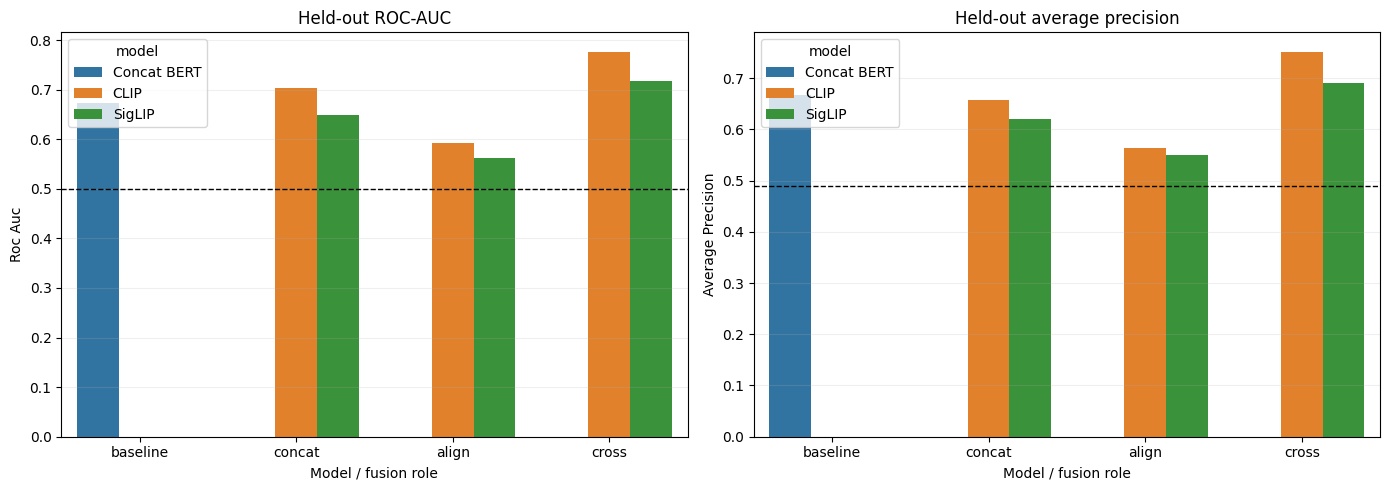

,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact,display_fusion
0,0.6732,0.6670,0.610,0.6069,0.5312,0.6462,0.4510,Concat BERT,Literature baseline,concat,0.6353,2,168625818,concat-bert--resnet152.pt,baseline
1,0.7039,0.6572,0.646,0.6442,0.6058,0.6667,0.5551,CLIP,Fusion + LPE,concat,0.6643,49,1025,clip--concat-linear-probe.pt,concat
2,0.5918,0.5635,0.490,0.5000,0.6577,0.4900,1.0000,CLIP,Fusion + LPE,align,0.6247,3,513,clip--align-linear-probe.pt,align
3,0.7769,0.7518,0.694,0.6916,0.6458,0.7460,0.5694,CLIP,Fusion + LPE,cross,0.7131,50,262145,clip--cross-linear-probe.pt,cross
4,0.6489,0.6207,0.619,0.6200,0.6326,0.5996,0.6694,SigLIP,Fusion + LPE,concat,0.6389,1,1537,siglip--concat-linear-probe.pt,concat
5,0.5619,0.5490,0.515,0.5209,0.6232,0.5031,0.8184,SigLIP,Fusion + LPE,align,0.6085,6,769,siglip--align-linear-probe.pt,align
6,0.7178,0.6896,0.661,0.6580,0.5940,0.7188,0.5061,SigLIP,Fusion + LPE,cross,0.6686,22,589825,siglip--cross-linear-probe.pt,cross


In [19]:
lpe_results = pd.concat(
    [clip_lpe_results, siglip_lpe_results],
    ignore_index=True,
)
lpe_results.to_csv(ARTIFACT_DIR / "fusion_lpe_metrics.csv", index=False)

lpe_prediction_frame = splits["test"].loc[:, ["id", "label"]].copy()
for (model_name, fusion), probabilities in lpe_probabilities.items():
    lpe_prediction_frame[f"{model_name.lower()}_{fusion}_lpe_probability"] = probabilities
lpe_prediction_frame.to_csv(
    ARTIFACT_DIR / "fusion_lpe_test_predictions.csv",
    index=False,
)

concat_bert_comparison = concat_bert_results.copy()
concat_bert_comparison["display_fusion"] = "baseline"
lpe_comparison = lpe_results.copy()
lpe_comparison["display_fusion"] = lpe_comparison["fusion"]
primary_model_results = pd.concat(
    [concat_bert_comparison, lpe_comparison],
    ignore_index=True,
)

model_order = {"Concat BERT": 0, "CLIP": 1, "SigLIP": 2}
fusion_order = {"baseline": 0, "concat": 1, "align": 2, "cross": 3}
primary_model_results = (
    primary_model_results
    .assign(
        _model_order=lambda frame: frame["model"].map(model_order),
        _fusion_order=lambda frame: frame["display_fusion"].map(fusion_order),
    )
    .sort_values(["_model_order", "_fusion_order"])
    .drop(columns=["_model_order", "_fusion_order"])
    .reset_index(drop=True)
)
primary_model_results.to_csv(
    ARTIFACT_DIR / "primary_model_metrics.csv",
    index=False,
)

primary_probabilities = {
    (CONCAT_BERT_NAME, "baseline"): concat_bert_test_probability,
    **lpe_probabilities,
}
primary_roc_auc_intervals = stratified_bootstrap_scores(
    y_true=test_labels,
    prediction_sets=primary_probabilities,
    metric=roc_auc_score,
    n_resamples=BOOTSTRAP_RESAMPLES,
)
primary_average_precision_intervals = stratified_bootstrap_scores(
    y_true=test_labels,
    prediction_sets=primary_probabilities,
    metric=average_precision_score,
    n_resamples=BOOTSTRAP_RESAMPLES,
)
primary_bootstrap_results = pd.DataFrame(
    [
        {
            "model": model_name,
            "fusion": fusion,
            "roc_auc_ci_lower": primary_roc_auc_intervals[key]["lower"],
            "roc_auc_ci_upper": primary_roc_auc_intervals[key]["upper"],
            "average_precision_ci_lower": primary_average_precision_intervals[key]["lower"],
            "average_precision_ci_upper": primary_average_precision_intervals[key]["upper"],
        }
        for key in primary_probabilities
        for model_name, fusion in [key]
    ]
)
primary_bootstrap_results.to_csv(
    ARTIFACT_DIR / "primary_model_bootstrap_intervals.csv",
    index=False,
)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, metric, title in zip(
    axes,
    ("roc_auc", "average_precision"),
    ("Held-out ROC-AUC", "Held-out average precision"),
):
    sns.barplot(
        data=primary_model_results,
        x="display_fusion",
        y=metric,
        hue="model",
        order=list(fusion_order),
        hue_order=list(model_order),
        ax=axis,
    )
    axis.set(title=title, xlabel="Model / fusion role", ylabel=metric.replace("_", " ").title())
    axis.grid(axis="y", alpha=0.2)
axes[0].axhline(0.5, color="black", linestyle="--", linewidth=1)
axes[1].axhline(test_labels.mean(), color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

primary_model_results.round(4)


## 11. Train direct-fusion ablations without LPE

These six ablations use the same frozen CLIP or SigLIP embeddings and the same concat, align, or cross label, but replace the linear readout with trainable modality projections and a nonlinear MLP classifier. They test whether the LPE constraint helps or hurts while retaining both modalities.


In [20]:
clip_direct_results = train_encoder_direct_fusions("CLIP")
clip_direct_results.to_csv(
    ARTIFACT_DIR / "clip_direct_fusion_ablation_metrics.csv",
    index=False,
)
clip_direct_results.round(4)


CLIP direct / concat: dev ROC-AUC=0.7061, test ROC-AUC=0.7417, epoch=11
CLIP direct / align: dev ROC-AUC=0.6930, test ROC-AUC=0.7260, epoch=10
CLIP direct / cross: dev ROC-AUC=0.7180, test ROC-AUC=0.7483, epoch=15


,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact
0,0.7417,0.7080,0.670,0.6679,0.6267,0.7030,0.5653,CLIP,Direct fusion ablation,concat,0.7061,11,82305,clip--concat-direct-fusion.pt
1,0.7260,0.7004,0.661,0.6594,0.6254,0.6819,0.5776,CLIP,Direct fusion ablation,align,0.6930,10,74113,clip--align-direct-fusion.pt
2,0.7483,0.7306,0.681,0.6795,0.6506,0.7021,0.6061,CLIP,Direct fusion ablation,cross,0.7180,15,590209,clip--cross-direct-fusion.pt


In [21]:
siglip_direct_results = train_encoder_direct_fusions("SigLIP")
siglip_direct_results.to_csv(
    ARTIFACT_DIR / "siglip_direct_fusion_ablation_metrics.csv",
    index=False,
)
siglip_direct_results.round(4)


SigLIP direct / concat: dev ROC-AUC=0.6804, test ROC-AUC=0.7066, epoch=5
SigLIP direct / align: dev ROC-AUC=0.6802, test ROC-AUC=0.7026, epoch=5
SigLIP direct / cross: dev ROC-AUC=0.6982, test ROC-AUC=0.7059, epoch=5


,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact
0,0.7066,0.6922,0.663,0.6610,0.6209,0.6917,0.5633,SigLIP,Direct fusion ablation,concat,0.6804,5,115073,siglip--concat-direct-fusion.pt
1,0.7026,0.6784,0.664,0.6625,0.6324,0.6816,0.5898,SigLIP,Direct fusion ablation,align,0.6802,5,106881,siglip--align-direct-fusion.pt
2,0.7059,0.6976,0.617,0.6115,0.4643,0.7378,0.3388,SigLIP,Direct fusion ablation,cross,0.6982,5,622977,siglip--cross-direct-fusion.pt


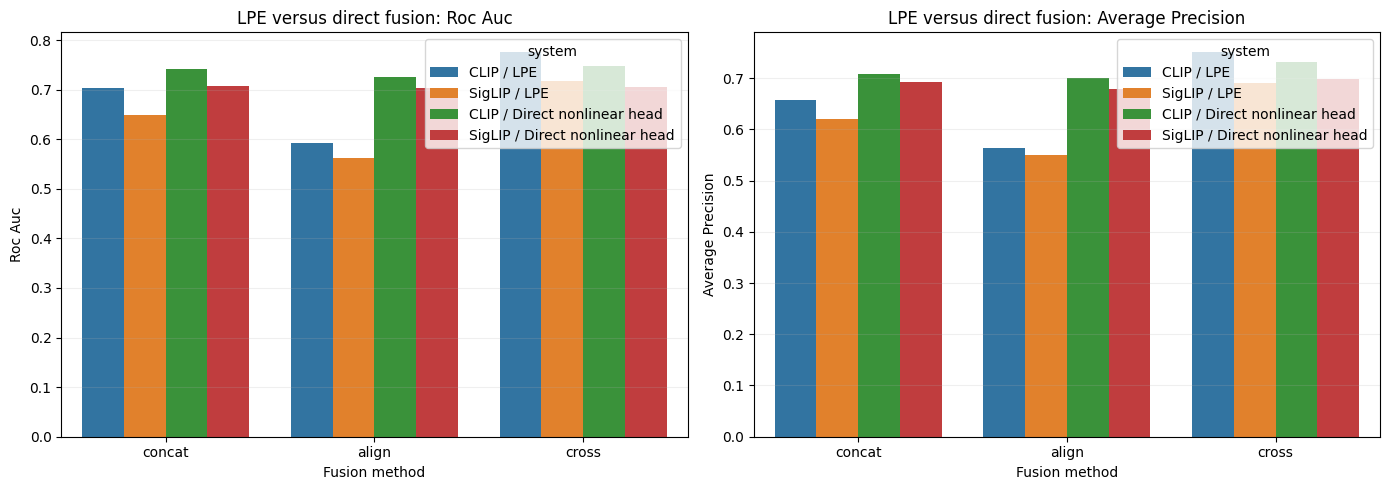

,roc_auc,average_precision,accuracy,balanced_accuracy,f1,precision,recall,model,family,fusion,dev_roc_auc,best_epoch,trainable_parameters,artifact,readout,system
7,0.7260,0.7004,0.661,0.6594,0.6254,0.6819,0.5776,CLIP,Direct fusion ablation,align,0.6930,10,74113,clip--align-direct-fusion.pt,Direct nonlinear head,CLIP / Direct nonlinear head
1,0.5918,0.5635,0.490,0.5000,0.6577,0.4900,1.0000,CLIP,Fusion + LPE,align,0.6247,3,513,clip--align-linear-probe.pt,LPE,CLIP / LPE
6,0.7417,0.7080,0.670,0.6679,0.6267,0.7030,0.5653,CLIP,Direct fusion ablation,concat,0.7061,11,82305,clip--concat-direct-fusion.pt,Direct nonlinear head,CLIP / Direct nonlinear head
0,0.7039,0.6572,0.646,0.6442,0.6058,0.6667,0.5551,CLIP,Fusion + LPE,concat,0.6643,49,1025,clip--concat-linear-probe.pt,LPE,CLIP / LPE
8,0.7483,0.7306,0.681,0.6795,0.6506,0.7021,0.6061,CLIP,Direct fusion ablation,cross,0.7180,15,590209,clip--cross-direct-fusion.pt,Direct nonlinear head,CLIP / Direct nonlinear head
2,0.7769,0.7518,0.694,0.6916,0.6458,0.7460,0.5694,CLIP,Fusion + LPE,cross,0.7131,50,262145,clip--cross-linear-probe.pt,LPE,CLIP / LPE
10,0.7026,0.6784,0.664,0.6625,0.6324,0.6816,0.5898,SigLIP,Direct fusion ablation,align,0.6802,5,106881,siglip--align-direct-fusion.pt,Direct nonlinear head,SigLIP / Direct nonlinear head
4,0.5619,0.5490,0.515,0.5209,0.6232,0.5031,0.8184,SigLIP,Fusion + LPE,align,0.6085,6,769,siglip--align-linear-probe.pt,LPE,SigLIP / LPE
9,0.7066,0.6922,0.663,0.6610,0.6209,0.6917,0.5633,SigLIP,Direct fusion ablation,concat,0.6804,5,115073,siglip--concat-direct-fusion.pt,Direct nonlinear head,SigLIP / Direct nonlinear head
3,0.6489,0.6207,0.619,0.6200,0.6326,0.5996,0.6694,SigLIP,Fusion + LPE,concat,0.6389,1,1537,siglip--concat-linear-probe.pt,LPE,SigLIP / LPE


In [22]:
direct_fusion_results = pd.concat(
    [clip_direct_results, siglip_direct_results],
    ignore_index=True,
)
direct_fusion_results.to_csv(
    ARTIFACT_DIR / "direct_fusion_ablation_metrics.csv",
    index=False,
)

direct_prediction_frame = splits["test"].loc[:, ["id", "label"]].copy()
for (model_name, fusion), probabilities in direct_fusion_probabilities.items():
    column = f"{model_name.lower()}_{fusion}_direct_probability"
    direct_prediction_frame[column] = probabilities
direct_prediction_frame.to_csv(
    ARTIFACT_DIR / "direct_fusion_ablation_predictions.csv",
    index=False,
)

head_ablation_results = pd.concat(
    [
        lpe_results.assign(readout="LPE"),
        direct_fusion_results.assign(readout="Direct nonlinear head"),
    ],
    ignore_index=True,
)
head_ablation_results["system"] = (
    head_ablation_results["model"] + " / " + head_ablation_results["readout"]
)
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, metric in zip(axes, ("roc_auc", "average_precision")):
    sns.barplot(
        data=head_ablation_results,
        x="fusion",
        y=metric,
        hue="system",
        errorbar=None,
        ax=axis,
    )
    axis.set(
        title=f"LPE versus direct fusion: {metric.replace('_', ' ').title()}",
        xlabel="Fusion method",
        ylabel=metric.replace("_", " ").title(),
    )
    axis.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

head_ablation_results.sort_values(["model", "fusion", "readout"]).round(4)


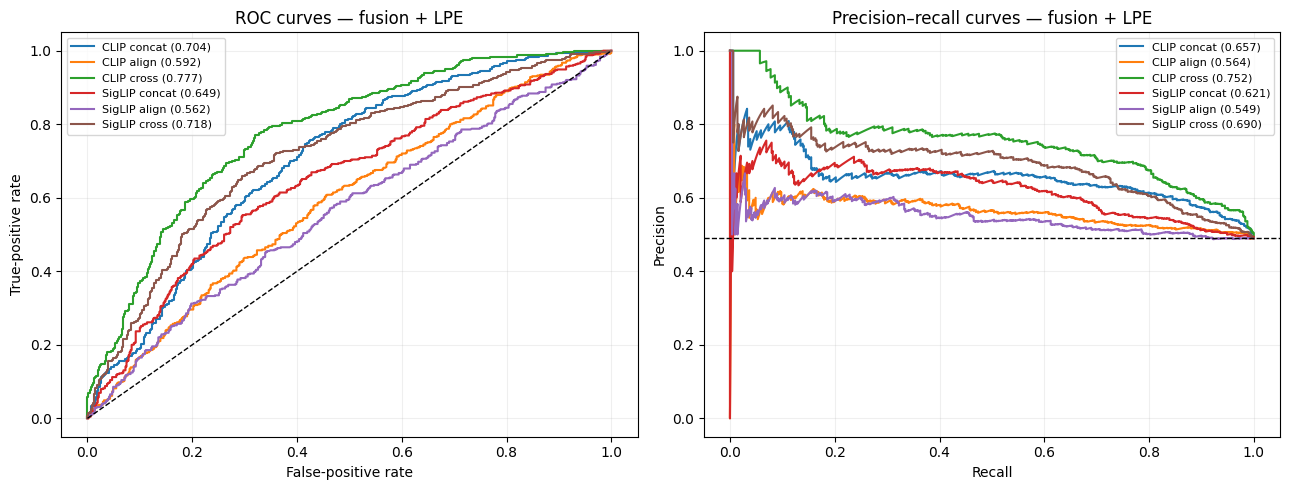

In [23]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for (model_name, fusion), probabilities in lpe_probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(test_labels, probabilities)
    precision, recall, _ = precision_recall_curve(test_labels, probabilities)
    roc_auc = roc_auc_score(test_labels, probabilities)
    average_precision = average_precision_score(test_labels, probabilities)
    label = f"{model_name} {fusion} ({roc_auc:.3f})"
    axes[0].plot(false_positive_rate, true_positive_rate, label=label)
    axes[1].plot(recall, precision, label=f"{model_name} {fusion} ({average_precision:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(title="ROC curves — fusion + LPE", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].axhline(test_labels.mean(), color="black", linestyle="--", linewidth=1)
axes[1].set(title="Precision–recall curves — fusion + LPE", xlabel="Recall", ylabel="Precision")
for axis in axes:
    axis.legend(fontsize=8)
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()


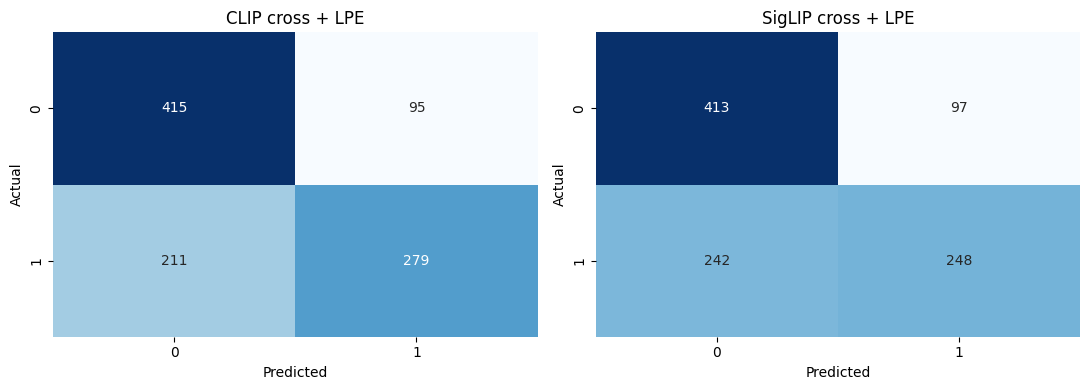

In [24]:
selected_lpe_fusions = (
    lpe_results.sort_values("dev_roc_auc", ascending=False)
    .groupby("model", as_index=False)
    .first()
    .set_index("model")["fusion"]
    .to_dict()
)

figure, axes = plt.subplots(1, len(MODEL_IDS), figsize=(11, 4))
for axis, model_name in zip(axes, MODEL_IDS):
    fusion = selected_lpe_fusions[model_name]
    probabilities = lpe_probabilities[(model_name, fusion)]
    predictions = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(test_labels, predictions)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis)
    axis.set(title=f"{model_name} {fusion} + LPE", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()


## 12. Qualitative error analysis of the fusion + LPE models

Quantitative metrics do not explain *why* a multimodal classifier fails. The next cell ranks confidently wrong predictions. Rendering remains opt-in because the material can be harmful; the compact table lets a reviewer inspect model confidence without automatically displaying images.


In [25]:
def error_frame(model_name, count=12):
    fusion = selected_lpe_fusions[model_name]
    frame = splits["test"].copy()
    frame["fusion"] = fusion
    frame["probability_hateful"] = lpe_probabilities[(model_name, fusion)]
    frame["prediction"] = (frame["probability_hateful"] >= 0.5).astype(int)
    mistakes = frame[frame["prediction"] != frame["label"]].copy()
    mistakes["confidence"] = np.where(
        mistakes["prediction"] == 1,
        mistakes["probability_hateful"],
        1.0 - mistakes["probability_hateful"],
    )
    return mistakes.sort_values("confidence", ascending=False).head(count)


errors = {model_name: error_frame(model_name) for model_name in MODEL_IDS}
for model_name, frame in errors.items():
    print(f"{model_name}: development-selected {selected_lpe_fusions[model_name]} fusion")
    display(frame[["id", "text", "label", "prediction", "probability_hateful", "fusion", "img"]])


CLIP: development-selected cross fusion


,id,text,label,prediction,probability_hateful,fusion,img
789,98137,life has its ups and downs,1,0,0.079390,cross,img/98137.png
839,16529,my dog loves the attention,1,0,0.090202,cross,img/16529.png
680,92015,good guy police officer capturing them young,1,0,0.104014,cross,img/92015.png
509,89140,burning things that don't mean anything to you,1,0,0.107556,cross,img/89140.png
478,28495,spending alot of time with your pets,1,0,0.111845,cross,img/28495.png
441,72419,"""nice watch must have cost an arm and a leg""",1,0,0.116517,cross,img/72419.png
952,35796,i hate it when white people throw gang signs t...,0,1,0.875503,cross,img/35796.png
793,23175,all men are pigs women are equal to men,0,1,0.858568,cross,img/23175.png
898,59031,how to get stoned without smoking weed,1,0,0.141495,cross,img/59031.png
136,17096,there use to be a pet shelter here,1,0,0.141692,cross,img/17096.png


SigLIP: development-selected cross fusion


,id,text,label,prediction,probability_hateful,fusion,img
743,95072,this guy just friended and unfriended me 45 ti...,1,0,0.065286,cross,img/95072.png
469,12589,"the religion of the muslims, a monotheistic fa...",0,1,0.913532,cross,img/12589.png
935,80231,"transrepublican identifies as a republican, bu...",1,0,0.090526,cross,img/80231.png
942,54196,let's not be hasty. the worldview of the guys ...,0,1,0.886602,cross,img/54196.png
952,35796,i hate it when white people throw gang signs t...,0,1,0.880047,cross,img/35796.png
547,80246,car salesman roof of car,1,0,0.127679,cross,img/80246.png
105,64735,this movie sucks i am thinking of another shoo...,1,0,0.138617,cross,img/64735.png
680,92015,good guy police officer capturing them young,1,0,0.142545,cross,img/92015.png
374,41896,me convincing homophobes that i'm just like th...,0,1,0.855238,cross,img/41896.png
427,34602,error,1,0,0.151457,cross,img/34602.png


In [26]:
def show_error_examples(model_name, count=6):
    examples = errors[model_name].head(count)
    columns = 3
    rows = int(np.ceil(len(examples) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(14, 4 * rows))
    axes = np.asarray(axes).reshape(-1)
    for axis, (_, row) in zip(axes, examples.iterrows()):
        axis.imshow(Image.open(resolve_image_path(row["img"])).convert("RGB"))
        axis.set_title(
            f"{model_name} | y={row['label']} p={row['probability_hateful']:.2f}\n"
            f"{row['text'][:90]}"
        )
        axis.axis("off")
    for axis in axes[len(examples):]:
        axis.axis("off")
    plt.tight_layout()


if SHOW_EXAMPLES:
    show_error_examples("CLIP")
    show_error_examples("SigLIP")


In [27]:
prediction_frame = splits["test"].loc[:, ["id", "label"]].copy()
for (model_name, fusion), probabilities in lpe_probabilities.items():
    prediction_frame[f"{model_name.lower()}_{fusion}_lpe_probability"] = probabilities
for (model_name, fusion), probabilities in direct_fusion_probabilities.items():
    prediction_frame[f"{model_name.lower()}_{fusion}_direct_probability"] = probabilities
prediction_frame["concat_bert_probability"] = concat_bert_test_probability
prediction_frame.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
prediction_frame.head()


/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,id,label,clip_concat_lpe_probability,clip_align_lpe_probability,clip_cross_lpe_probability,siglip_concat_lpe_probability,siglip_align_lpe_probability,siglip_cross_lpe_probability,clip_concat_direct_probability,clip_align_direct_probability,clip_cross_direct_probability,siglip_concat_direct_probability,siglip_align_direct_probability,siglip_cross_direct_probability,concat_bert_probability
0,16395,1,0.408961,0.501976,0.436262,0.482214,0.499357,0.246123,0.631817,0.840465,0.981152,0.148135,0.313244,0.052468,0.600586
1,37405,1,0.655939,0.501851,0.794631,0.506380,0.500000,0.385205,0.734685,0.807362,0.985479,0.460707,0.561990,0.525789,0.471680
2,94180,1,0.642630,0.501538,0.711690,0.507861,0.500475,0.743840,0.968093,0.944414,0.990223,0.893775,0.758832,0.470663,0.843750
3,54321,1,0.503611,0.501921,0.408570,0.515812,0.501429,0.542285,0.701835,0.469420,0.829634,0.563870,0.614107,0.381276,0.489258
4,97015,1,0.828007,0.502564,0.923876,0.530064,0.501373,0.840293,0.912412,0.918520,0.999853,0.929339,0.808817,0.945311,0.611328


## 13. Interpreting the completed run

After running all cells, report exact held-out results by model family rather than making a general claim that one encoder is better. A useful summary should answer:

1. Which fusion-specific LPE performs best for CLIP and for SigLIP based on development selection and held-out evaluation?
2. Does concat, align, or cross fusion behave consistently across the two encoders?
3. How do the six frozen-encoder LPE systems compare with the end-to-end Concat BERT baseline?
4. For each fusion method, does replacing LPE with the direct nonlinear fusion head improve or reduce held-out performance?
5. Are errors concentrated in false positives or false negatives, and what patterns appear in confidently wrong examples?

Use `primary_model_metrics.csv` for the headline seven-model comparison and `direct_fusion_ablation_metrics.csv` only for the no-LPE ablation discussion. Do not mix the two tables when stating the primary result.

### Limitations and responsible use

- CLIP and SigLIP remain frozen; the experiment evaluates their representations rather than end-to-end fine-tuning.
- Cross-fusion LPE uses a bilinear classifier, which is linear over the outer-product feature map without explicitly materializing it.
- The direct fusion heads are nonlinear ablations, not LPE models.
- Concat BERT is a current-library reproduction of a literature baseline, not a bit-for-bit recreation of an older training environment.
- Dataset performance does not establish readiness for real moderation. Deployment would require subgroup fairness analysis, calibration, human review, appeals, and monitoring for distribution shift.
- The dataset license and access terms apply. Images and annotations should not be committed to this repository.


In [30]:
environment["elapsed_minutes"] = round(
    (perf_counter() - RUN_STARTED_AT) / 60,
    1,
)
(ARTIFACT_DIR / "run_metadata.json").write_text(
    json.dumps(environment, indent=2), encoding="utf-8"
)
environment


NameError: name 'environment' is not defined